# Second CNN experiment with Plant CNN Starter 300

This notebook trains the same custom `PlantCNN` architecture with freshly
initialized weights on the attached `Plant_CNN_Starter_300` dataset. Run cells
from top to bottom with **Shift + Enter**, using **Python (LeafCheck)**.

| Split | Images per class | Total | Purpose |
| --- | --- | --- | --- |
| `train` | 70 | 210 | Update model weights |
| `val` | 20 | 60 | Select the checkpoint using validation loss |
| `test` | 10 | 30 | Evaluate after checkpoint selection |
| `quick_check_15` | 5 | 15 | Debug using convenience copies of training images |

The notebook verifies the supplied manifest, performs a 15-image learning check,
trains a new model on all 210 training images, reloads the selected checkpoint,
and reports validation and test metrics. Each run saves its outputs under
`runs/leafcheck_starter300/`.

The architecture, 128-pixel input, optimizer settings, seed, maximum 10 epochs,
and deterministic preprocessing follow the first experiment. The dataset and
split sizes have changed. A score difference from the earlier run cannot by
itself establish that the model improved, because the evaluation images differ.

**Running every cell includes the final test evaluation.** Use validation data
for future model changes. Report that the 30-image test has already been evaluated
if you make further changes after inspecting its results.

To install dependencies, activate `.venv` in a terminal and run
`python -m pip install -r requirements.txt`. Launch JupyterLab from the project
root with `python -m jupyterlab`.

## 1. Environment and settings

Run this cell first. `DATA_ROOT` points to the attached dataset. Its validation
directory is named `val`. `EPOCHS` is the maximum number of training passes and
`PATIENCE` controls early stopping. The same baseline settings are used throughout
this run. Each training cell constructs a fresh model and optimizer.

In [1]:
import csv
import hashlib
import json
import random
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torchvision
from PIL import Image, ImageOps
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import ImageFolder
from torchvision.transforms.functional import to_tensor

PROJECT_ROOT = Path.cwd().resolve()
DATA_ROOT = PROJECT_ROOT / "Plant_CNN_Starter_300"
SEED = 434
INPUT_SIZE = 128
TINY_UPDATES = 100
BATCH_SIZE = 16
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001
DROPOUT = 0.2
EPOCHS = 10
PATIENCE = 5
DEVICE_PREFERENCE = "auto"

assert (DATA_ROOT / "train").is_dir(), (
    "Set PROJECT_ROOT to your ML-Final-Project folder, then run from this cell again."
)
assert DEVICE_PREFERENCE in {"auto", "cpu", "mps"}

def set_seed(seed):
    random.seed(seed)
    torch.manual_seed(seed)

set_seed(SEED)
if DEVICE_PREFERENCE == "auto":
    device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
else:
    device = torch.device(DEVICE_PREFERENCE)

environment = {
    "python": sys.version,
    "python_executable": sys.executable,
    "torch": str(torch.__version__),
    "torchvision": str(torchvision.__version__),
    "pillow": Image.__version__,
    "device": str(device),
}
print(json.dumps(environment, indent=2))
print("Device calculation:", torch.ones(2, device=device) + 1)

{
  "python": "3.14.7 (main, Aug  5 2026, 10:29:49) [Clang 21.0.0 (clang-2100.1.1.101)]",
  "python_executable": "/Users/jacobamey/Desktop/Brockport_Class/ML-Final-Project/.venv/bin/python",
  "torch": "2.15.0",
  "torchvision": "0.29.2",
  "pillow": "13.0.0",
  "device": "mps"
}
Device calculation: tensor([2., 2.], device='mps:0')


## 2. Verify the main dataset and the 15 training copies

Check every manifest row against the file bytes and declared image dimensions.
Also check exact decoded RGB copies under all rotations and flips, and require
distinct recorded parent groups. These checks do not establish biological label
correctness or detect every possible near-duplicate or shared plant.

The quick-check files must match their named training originals. They remain a
separate debugging view of training data. This audit checks test file integrity
before training, while prediction metrics are calculated after selection.

In [2]:
with (DATA_ROOT / "class_to_idx.json").open() as file:
    expected_mapping = json.load(file)
assert expected_mapping == {
    "tomato__early_blight": 0,
    "tomato__healthy": 1,
    "tomato__late_blight": 2,
}
with (DATA_ROOT / "manifest.csv").open(newline="") as file:
    manifest_rows = list(csv.DictReader(file))

expected_split_sizes = {"train": 210, "val": 60, "test": 30}
split_counts = {split: 0 for split in expected_split_sizes}
class_counts = {
    split: {name: 0 for name in expected_mapping}
    for split in expected_split_sizes
}
file_hashes, pixel_fingerprints, parent_groups, relative_paths = set(), set(), set(), set()
for row in manifest_rows:
    relative_path = Path(row["output_relative_path"])
    path = (DATA_ROOT / relative_path).resolve()
    assert path.is_relative_to(DATA_ROOT.resolve())
    assert relative_path.parts[:2] == (row["split"], row["class_name"])
    assert int(row["class_id"]) == expected_mapping[row["class_name"]]
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    assert digest == row["sha256"] and digest not in file_hashes
    with Image.open(path) as image:
        image.load()
        assert image.mode == row["mode"] == "RGB"
        assert image.size == (int(row["width"]), int(row["height"])) == (256, 256)
        image = ImageOps.exif_transpose(image).convert("RGB")
        fingerprints = [hashlib.sha256(image.tobytes()).hexdigest()]
        fingerprints.extend(
            hashlib.sha256(image.transpose(operation).tobytes()).hexdigest()
            for operation in Image.Transpose
        )
        pixel_fingerprint = min(fingerprints)
    assert pixel_fingerprint not in pixel_fingerprints
    assert row["parent_group_id"] and row["parent_group_id"] not in parent_groups
    assert row["output_relative_path"] not in relative_paths
    file_hashes.add(digest)
    pixel_fingerprints.add(pixel_fingerprint)
    parent_groups.add(row["parent_group_id"])
    relative_paths.add(row["output_relative_path"])
    split_counts[row["split"]] += 1
    class_counts[row["split"]][row["class_name"]] += 1
assert split_counts == expected_split_sizes
for split, total in expected_split_sizes.items():
    assert set(class_counts[split].values()) == {total // 3}
    actual_files = {
        path.relative_to(DATA_ROOT).as_posix()
        for path in (DATA_ROOT / split).rglob("*.jpg")
    }
    expected_files = {r["output_relative_path"] for r in manifest_rows if r["split"] == split}
    assert actual_files == expected_files

with (DATA_ROOT / "quick_check_15/manifest.csv").open(newline="") as file:
    quick_rows = list(csv.DictReader(file))
main_by_path = {row["output_relative_path"]: row for row in manifest_rows}
quick_paths = set()
for row in quick_rows:
    training_row = main_by_path[row["training_relative_path"]]
    assert training_row["split"] == "train"
    assert row["class_name"] == training_row["class_name"]
    assert row["class_id"] == training_row["class_id"]
    assert row["output_relative_path"] not in quick_paths
    quick_paths.add(row["output_relative_path"])
    assert hashlib.sha256((DATA_ROOT / row["output_relative_path"]).read_bytes()).hexdigest() == row["sha256"]
    assert row["sha256"] == training_row["sha256"]
assert len(quick_rows) == 15
assert quick_paths == {
    path.relative_to(DATA_ROOT).as_posix()
    for path in (DATA_ROOT / "quick_check_15").rglob("*.jpg")
}

dataset_audit = {
    "dataset": DATA_ROOT.name,
    "manifest_sha256": hashlib.sha256((DATA_ROOT / "manifest.csv").read_bytes()).hexdigest(),
    "unique_main_images": len(manifest_rows),
    "split_counts": split_counts,
    "class_counts": class_counts,
    "recorded_parent_groups": len(parent_groups),
    "quick_check_training_copies": len(quick_rows),
    "distinct_main_file_hashes": len(file_hashes),
    "distinct_main_rotation_flip_fingerprints": len(pixel_fingerprints),
}
print(json.dumps(dataset_audit, indent=2))

{
  "dataset": "Plant_CNN_Starter_300",
  "manifest_sha256": "41bd4c22b2fa8afc600468de0bd9f8ed29201fb50ee1b82b03a6ba6990b1ef8b",
  "unique_main_images": 300,
  "split_counts": {
    "train": 210,
    "val": 60,
    "test": 30
  },
  "class_counts": {
    "train": {
      "tomato__early_blight": 70,
      "tomato__healthy": 70,
      "tomato__late_blight": 70
    },
    "val": {
      "tomato__early_blight": 20,
      "tomato__healthy": 20,
      "tomato__late_blight": 20
    },
    "test": {
      "tomato__early_blight": 10,
      "tomato__healthy": 10,
      "tomato__late_blight": 10
    }
  },
  "recorded_parent_groups": 300,
  "quick_check_training_copies": 15,
  "distinct_main_file_hashes": 300,
  "distinct_main_rotation_flip_fingerprints": 300
}


## 3. Prepare images and load the training and validation splits

Apply orientation correction, RGB conversion, bilinear resize and gray padding to
128 × 128, then scale bytes to a float32 tensor in [0, 1]. Every split and prediction
uses this loader. These baseline experiments use deterministic preprocessing.
The class names include the `tomato__` prefix supplied by this dataset.

In [3]:
def load_leaf(path):
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image).convert("RGB")
        image = ImageOps.pad(
            image,
            (INPUT_SIZE, INPUT_SIZE),
            method=Image.Resampling.BILINEAR,
            color=(128, 128, 128),
        )
        return to_tensor(image)

train_data = ImageFolder(DATA_ROOT / "train", loader=load_leaf)
validation_data = ImageFolder(DATA_ROOT / "val", loader=load_leaf)
assert train_data.class_to_idx == validation_data.class_to_idx == expected_mapping
class_names = train_data.classes

example, example_label = train_data[0]
assert example.shape == (3, INPUT_SIZE, INPUT_SIZE)
assert example.dtype == torch.float32
assert 0 <= example.min().item() <= example.max().item() <= 1
print("Training images available:", len(train_data))
print("Validation images:", len(validation_data))
print("Class order:", class_names)
print("Example shape and label:", example.shape, example_label)

Training images available: 210
Validation images: 60
Class order: ['tomato__early_blight', 'tomato__healthy', 'tomato__late_blight']
Example shape and label: torch.Size([3, 128, 128]) 0


## 4. Inspect the 15-image training batch

The convenience folder has five training images per class. It is used only for
the forward-pass and tiny learning checks. The later experiment uses a fresh model
and all 210 files from `train`.

Quick-check batch: torch.Size([15, 3, 128, 128]) torch.Size([15])
Training and validation counts: 210 60


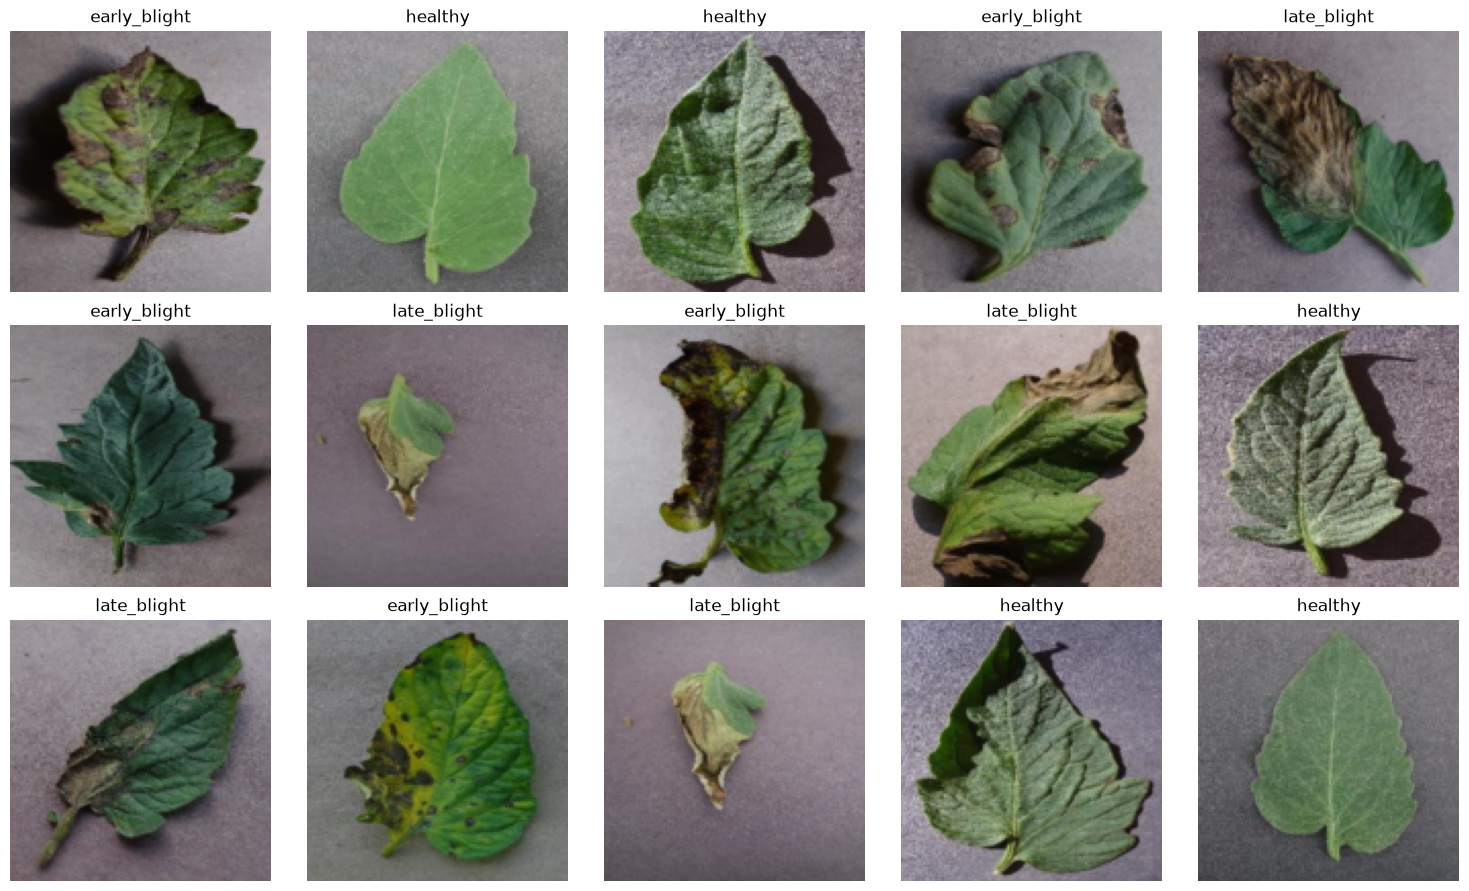

In [4]:
tiny_data = ImageFolder(DATA_ROOT / "quick_check_15", loader=load_leaf)
assert tiny_data.class_to_idx == expected_mapping
tiny_loader = DataLoader(
    tiny_data, batch_size=len(tiny_data), shuffle=True, num_workers=0,
    generator=torch.Generator().manual_seed(SEED),
)
images, labels = next(iter(tiny_loader))
assert images.shape == (15, 3, INPUT_SIZE, INPUT_SIZE)
assert labels.dtype == torch.long
assert torch.bincount(labels, minlength=3).tolist() == [5, 5, 5]
print("Quick-check batch:", images.shape, labels.shape)
print("Training and validation counts:", len(train_data), len(validation_data))

figure, axes = plt.subplots(3, 5, figsize=(15, 9))
for axis, image, label in zip(axes.flat, images, labels):
    axis.imshow(image.permute(1, 2, 0))
    axis.set_title(class_names[label.item()].removeprefix("tomato__"))
    axis.axis("off")
figure.tight_layout()
plt.show()

## 5. Define the custom CNN and verify a parameter update

The architecture matches the previous experiment. Three convolution blocks with
16, 32, and 64 filters reduce a 128-pixel input to 16 × 16 feature maps. Global
average pooling produces 64 features per image, and the linear output produces
three raw logits. Batch normalization and dropout use training and evaluation
modes. Each constructor call initializes a separate set of weights.

| Component | Output shape |
| --- | --- |
| Input | B × 3 × 128 × 128 |
| Block 1 | B × 16 × 64 × 64 |
| Block 2 | B × 32 × 32 × 32 |
| Block 3 | B × 64 × 16 × 16 |
| Global average pooling and flatten | B × 64 |
| Dropout and linear output | B × 3 |

In [5]:
class PlantCNN(nn.Module):
    def __init__(self, num_classes=3, dropout=0.2):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(start_dim=1),
            nn.Dropout(dropout),
            nn.Linear(64, num_classes),
        )

    def forward(self, images):
        return self.classifier(self.features(images))

In [6]:
def check_one_update(images, labels):
    set_seed(SEED)
    model = PlantCNN(len(class_names), dropout=0.0).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.0)
    loss_fn = nn.CrossEntropyLoss()
    batch_images, batch_labels = images.to(device), labels.to(device)

    model.eval()
    with torch.no_grad():
        logits = model(batch_images)
    assert logits.shape == (len(labels), len(class_names))
    parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
    assert parameter_count == 23891

    before = model.features[0].weight.detach().clone()
    model.train()
    optimizer.zero_grad()
    loss = loss_fn(model(batch_images), batch_labels)
    assert torch.isfinite(loss).item()
    loss.backward()
    gradient = model.features[0].weight.grad
    assert gradient is not None and torch.isfinite(gradient).all().item()
    optimizer.step()
    change = (model.features[0].weight.detach() - before).abs().max().item()
    assert change > 0
    print("Output shape:", logits.shape)
    print("Trainable parameters:", parameter_count)
    print("Finite training loss:", loss.item())
    print("Maximum first-layer weight change:", change)

check_one_update(images, labels)

Output shape: torch.Size([15, 3])
Trainable parameters: 23891
Finite training loss: 1.1116809844970703
Maximum first-layer weight change: 0.0010000020265579224


## 6. Training and evaluation functions

Cross-entropy receives raw logits and integer targets. Training clears gradients,
runs the forward pass, computes loss, backpropagates, and updates weights.
Evaluation disables gradients and uses stored batch-normalization statistics.

Loss is weighted by batch size before averaging across examples. Macro F1 gives
each class equal weight. Precision and recall use zero when their denominator is
zero. Confusion matrices use actual classes as rows and predicted classes as columns.

In [7]:
def classification_metrics(targets, predictions):
    number_of_classes = len(class_names)
    matrix = torch.bincount(
        targets * number_of_classes + predictions,
        minlength=number_of_classes ** 2,
    ).reshape(number_of_classes, number_of_classes)

    true_positive = matrix.diag().float()
    support = matrix.sum(dim=1)
    precision = true_positive / matrix.sum(dim=0).clamp_min(1)
    recall = true_positive / support.clamp_min(1)
    f1 = 2 * precision * recall / (precision + recall).clamp_min(1e-12)
    return {
        "accuracy": true_positive.sum().item() / targets.numel(),
        "macro_f1": f1.mean().item(),
        "confusion_matrix": matrix.tolist(),
        "per_class": [
            {
                "class_name": name,
                "precision": precision[index].item(),
                "recall": recall[index].item(),
                "f1": f1[index].item(),
                "support": support[index].item(),
            }
            for index, name in enumerate(class_names)
        ],
    }

def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0
    for batch_images, batch_labels in loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)
        optimizer.zero_grad()
        logits = model(batch_images)
        loss = loss_fn(logits, batch_labels)
        if not torch.isfinite(loss).item():
            raise RuntimeError("Training loss is nonfinite. Check inputs and learning rate.")
        loss.backward()
        optimizer.step()

        batch_size = batch_labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(dim=1) == batch_labels).sum().item()
        total_examples += batch_size
    return {
        "loss": total_loss / total_examples,
        "accuracy": total_correct / total_examples,
    }

@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss = 0.0
    targets, predictions = [], []
    for batch_images, batch_labels in loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)
        logits = model(batch_images)
        loss = loss_fn(logits, batch_labels)
        if not torch.isfinite(loss).item():
            raise RuntimeError("Evaluation loss is nonfinite.")
        total_loss += loss.item() * batch_labels.size(0)
        targets.append(batch_labels.cpu())
        predictions.append(logits.argmax(dim=1).cpu())
    targets = torch.cat(targets)
    metrics = classification_metrics(targets, torch.cat(predictions))
    metrics["loss"] = total_loss / targets.numel()
    return metrics

## 7. Fit the 15 training images as a learning check

This diagnostic model uses zero dropout and weight decay. Observe whether the
recorded loss drops and the correct count increases. A temporary rise in
evaluation-mode loss can occur while batch-normalization statistics develop.
The following experiment constructs a fresh model.

Update  10 | loss 1.1204 | correct 5/15
Update  20 | loss 1.2411 | correct 5/15
Update  30 | loss 1.2631 | correct 7/15
Update  40 | loss 1.0787 | correct 10/15
Update  50 | loss 0.8780 | correct 10/15
Update  60 | loss 0.4276 | correct 11/15
Update  70 | loss 0.1296 | correct 15/15
Update  80 | loss 0.0612 | correct 15/15
Update  90 | loss 0.0441 | correct 15/15
Update 100 | loss 0.0296 | correct 15/15


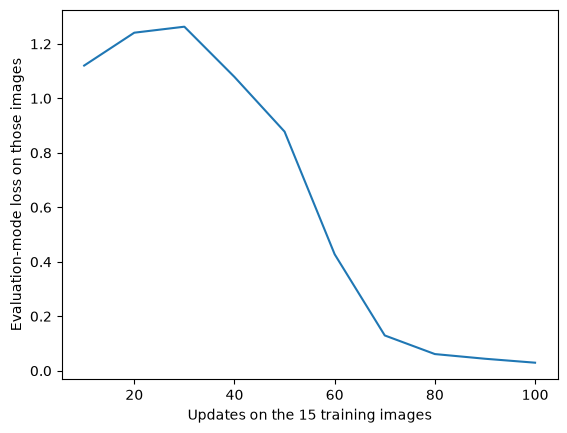

In [8]:
def run_tiny_check():
    set_seed(SEED)
    tiny_model = PlantCNN(len(class_names), dropout=0.0).to(device)
    optimizer = torch.optim.AdamW(
        tiny_model.parameters(), lr=LEARNING_RATE, weight_decay=0.0,
    )
    loss_fn = nn.CrossEntropyLoss()
    batch_images, batch_labels = images.to(device), labels.to(device)
    history = []

    for update in range(1, TINY_UPDATES + 1):
        tiny_model.train()
        optimizer.zero_grad()
        loss = loss_fn(tiny_model(batch_images), batch_labels)
        assert torch.isfinite(loss).item()
        loss.backward()
        optimizer.step()

        if update % 10 == 0 or update == TINY_UPDATES:
            tiny_model.eval()
            with torch.no_grad():
                logits = tiny_model(batch_images)
                checked_loss = loss_fn(logits, batch_labels).item()
                correct = (logits.argmax(dim=1) == batch_labels).sum().item()
            history.append({"update": update, "loss": checked_loss, "correct": correct})
            print(f"Update {update:3d} | loss {checked_loss:.4f} | correct {correct}/{len(tiny_data)}")
    return history

tiny_history = run_tiny_check()
plt.plot([row["update"] for row in tiny_history], [row["loss"] for row in tiny_history])
plt.xlabel("Updates on the 15 training images")
plt.ylabel("Evaluation-mode loss on those images")
plt.show()

## 8. Train all 210 images and select the checkpoint using validation loss

The training set has 14 batches at batch size 16, with two images in its final
batch. The validation set contains 60 images. Each execution of this cell creates
a fresh model, optimizer, and run directory. Early stopping applies after five
consecutive epochs without lower validation loss, up to 10 epochs total.

Save a checkpoint immediately when validation loss improves. The checkpoint
includes a snapshot of model weights, class order, model settings, and reference
logits for a fixed validation batch. Test scores do not participate in selection.

In [9]:
set_seed(SEED)
training_loader = DataLoader(
    train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
    generator=torch.Generator().manual_seed(SEED),
)
validation_loader = DataLoader(
    validation_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
)
reference_images, _ = next(iter(validation_loader))
model = PlantCNN(len(class_names), dropout=DROPOUT).to(device)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
)
loss_fn = nn.CrossEntropyLoss()

run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
run_dir = PROJECT_ROOT / "runs/leafcheck_starter300" / run_id
run_dir.mkdir(parents=True, exist_ok=False)
checkpoint_path = run_dir / "best_model.pt"
config = {
    "model_version": "leafcheck-starter300-v1",
    "seed": SEED,
    "input_size": INPUT_SIZE,
    "dataset": DATA_ROOT.name,
    "manifest_sha256": dataset_audit["manifest_sha256"],
    "train_images": len(train_data),
    "validation_images": len(validation_data),
    "tiny_updates": TINY_UPDATES,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "dropout": DROPOUT,
    "max_epochs": EPOCHS,
    "early_stopping_patience": PATIENCE,
    "checkpoint_selection": "minimum validation loss",
    "preprocessing": "EXIF transpose, RGB, bilinear pad to square with RGB 128, tensor /255",
    "augmentation": "none",
    "environment": environment,
}
(run_dir / "config.json").write_text(json.dumps(config, indent=2))
(run_dir / "class_to_idx.json").write_text(json.dumps(train_data.class_to_idx, indent=2))
(run_dir / "dataset_audit.json").write_text(json.dumps(dataset_audit, indent=2))
with (run_dir / "dataset_manifest.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(manifest_rows[0]))
    writer.writeheader()
    writer.writerows(manifest_rows)
with (run_dir / "quick_check_manifest.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(quick_rows[0]))
    writer.writeheader()
    writer.writerows(quick_rows)
with (run_dir / "tiny_history.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(tiny_history[0]))
    writer.writeheader()
    writer.writerows(tiny_history)

history = []
best_loss = float("inf")
epochs_without_improvement = 0
print("Run folder:", run_dir)
for epoch in range(1, EPOCHS + 1):
    started = time.perf_counter()
    training = train_one_epoch(model, training_loader, loss_fn, optimizer)
    validation = evaluate(model, validation_loader, loss_fn)
    row = {
        "epoch": epoch,
        "train_loss": training["loss"],
        "train_accuracy": training["accuracy"],
        "validation_loss": validation["loss"],
        "validation_accuracy": validation["accuracy"],
        "validation_macro_f1": validation["macro_f1"],
        "seconds": time.perf_counter() - started,
    }
    history.append(row)
    with (run_dir / "history.csv").open("w", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=list(row))
        writer.writeheader()
        writer.writerows(history)

    print(
        f"Epoch {epoch:2d}/{EPOCHS} | train loss {training['loss']:.4f} "
        f"acc {training['accuracy']:.1%} | val loss {validation['loss']:.4f} "
        f"acc {validation['accuracy']:.1%} F1 {validation['macro_f1']:.3f} "
        f"| {row['seconds']:.1f}s"
    )
    if validation["loss"] < best_loss:
        best_loss = validation["loss"]
        epochs_without_improvement = 0
        with torch.no_grad():
            reference_logits = model(reference_images.to(device)).cpu().clone()
        checkpoint = {
            "model_state_dict": {
                name: value.detach().cpu().clone()
                for name, value in model.state_dict().items()
            },
            "classes": class_names,
            "model_config": {"num_classes": len(class_names), "dropout": DROPOUT},
            "input_size": INPUT_SIZE,
            "epoch": epoch,
            "validation_loss": best_loss,
            "reference_logits": reference_logits,
            "config": config,
        }
        temporary_path = checkpoint_path.with_suffix(".tmp")
        torch.save(checkpoint, temporary_path)
        temporary_path.replace(checkpoint_path)
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print("Early stopping after consecutive epochs without lower validation loss.")
            break

Run folder: /Users/jacobamey/Desktop/Brockport_Class/ML-Final-Project/runs/leafcheck_starter300/20261115T230136_680592Z
Epoch  1/10 | train loss 0.9901 acc 54.3% | val loss 1.0957 acc 33.3% F1 0.167 | 0.5s
Epoch  2/10 | train loss 0.7871 acc 65.7% | val loss 1.0258 acc 33.3% F1 0.167 | 0.3s
Epoch  3/10 | train loss 0.7123 acc 72.9% | val loss 0.8427 acc 61.7% F1 0.558 | 0.3s
Epoch  4/10 | train loss 0.6632 acc 76.2% | val loss 1.6442 acc 38.3% F1 0.315 | 0.3s
Epoch  5/10 | train loss 0.6872 acc 73.3% | val loss 0.8010 acc 61.7% F1 0.496 | 0.3s
Epoch  6/10 | train loss 0.6152 acc 78.6% | val loss 0.7185 acc 68.3% F1 0.609 | 0.3s
Epoch  7/10 | train loss 0.5825 acc 78.6% | val loss 0.8609 acc 63.3% F1 0.531 | 0.3s
Epoch  8/10 | train loss 0.4748 acc 88.6% | val loss 1.1986 acc 43.3% F1 0.343 | 0.3s
Epoch  9/10 | train loss 0.4562 acc 86.7% | val loss 0.5015 acc 81.7% F1 0.819 | 0.3s
Epoch 10/10 | train loss 0.4208 acc 87.6% | val loss 2.5600 acc 38.3% F1 0.260 | 0.3s


## 9. Restore the selected checkpoint and verify validation predictions

Load saved weights into a new model, then compare reference logits with those saved
at the selected epoch. Recalculate validation metrics for the same checkpoint.
These scores were used during model selection.

In [10]:
checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
assert checkpoint["classes"] == class_names
assert checkpoint["input_size"] == INPUT_SIZE
restored_model = PlantCNN(**checkpoint["model_config"]).to(device)
restored_model.load_state_dict(checkpoint["model_state_dict"])
restored_model.eval()
with torch.no_grad():
    restored_logits = restored_model(reference_images.to(device)).cpu()
torch.testing.assert_close(
    restored_logits, checkpoint["reference_logits"], rtol=1e-4, atol=1e-5,
)
print("Checkpoint prediction comparison passed.")

validation_metrics = evaluate(restored_model, validation_loader, loss_fn)
selected_row = next(row for row in history if row["epoch"] == checkpoint["epoch"])
assert abs(validation_metrics["loss"] - selected_row["validation_loss"]) < 1e-5
assert validation_metrics["accuracy"] == selected_row["validation_accuracy"]
print("Selected epoch:", checkpoint["epoch"])
print(f"Validation loss: {validation_metrics['loss']:.4f}")
print(f"Validation accuracy: {validation_metrics['accuracy']:.1%}")
print(f"Validation macro F1: {validation_metrics['macro_f1']:.3f}")
for row in validation_metrics["per_class"]:
    print(
        f"{row['class_name']:14s} | precision {row['precision']:.3f} "
        f"recall {row['recall']:.3f} F1 {row['f1']:.3f} | count {row['support']}"
    )
validation_metrics["selected_epoch"] = checkpoint["epoch"]
(run_dir / "validation_metrics.json").write_text(json.dumps(validation_metrics, indent=2))

Checkpoint prediction comparison passed.
Selected epoch: 9
Validation loss: 0.5015
Validation accuracy: 81.7%
Validation macro F1: 0.819
tomato__early_blight | precision 0.750 recall 0.750 F1 0.750 | count 20
tomato__healthy | precision 1.000 recall 0.950 F1 0.974 | count 20
tomato__late_blight | precision 0.714 recall 0.750 F1 0.732 | count 20


764

## 10. Plot the learning curves and validation confusion matrix

Inspect both losses and the per-class errors. The dashed line identifies the
epoch selected by minimum validation loss. Accuracy may peak at a different epoch.

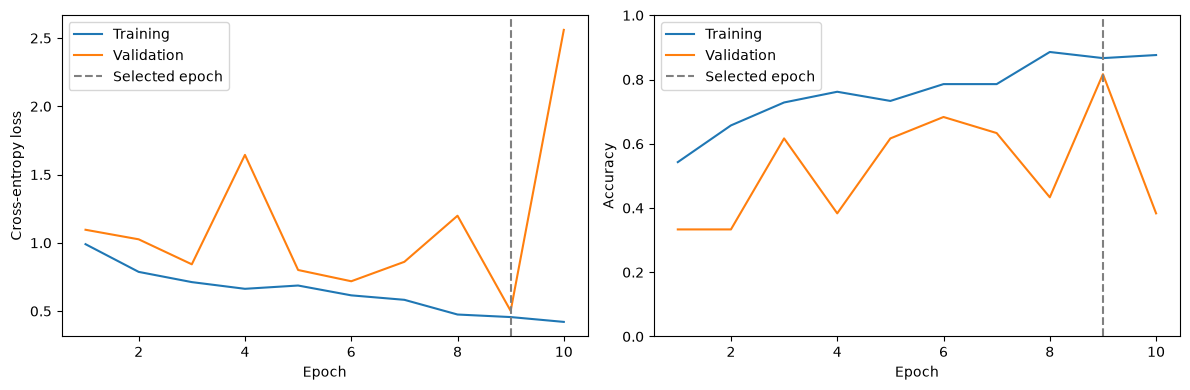

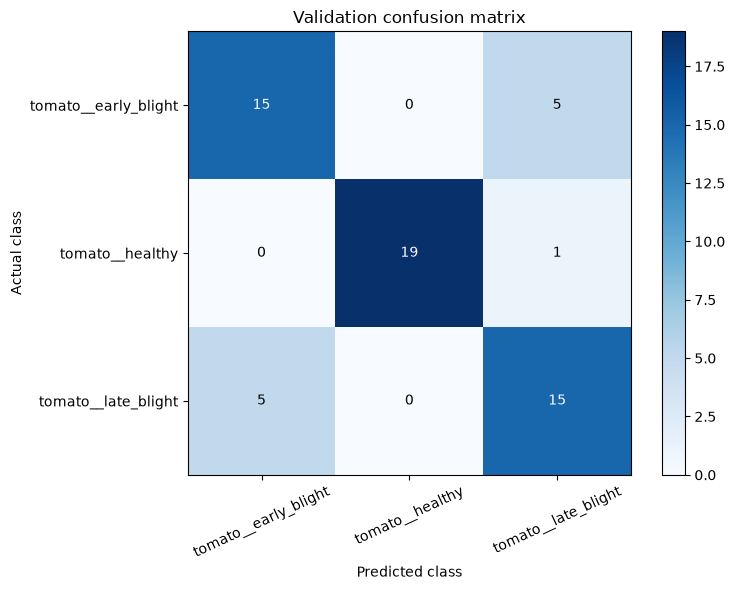

In [11]:
epochs = [row["epoch"] for row in history]
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, [row["train_loss"] for row in history], label="Training")
axes[0].plot(epochs, [row["validation_loss"] for row in history], label="Validation")
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss")
axes[1].plot(epochs, [row["train_accuracy"] for row in history], label="Training")
axes[1].plot(epochs, [row["validation_accuracy"] for row in history], label="Validation")
axes[1].set(xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1))
for axis in axes:
    axis.axvline(checkpoint["epoch"], color="gray", linestyle="--", label="Selected epoch")
    axis.legend()
figure.tight_layout()
figure.savefig(run_dir / "learning_curves.png", dpi=160)
plt.show()

matrix = validation_metrics["confusion_matrix"]
figure, axis = plt.subplots(figsize=(8, 6))
heatmap = axis.imshow(matrix, cmap="Blues")
figure.colorbar(heatmap, ax=axis)
axis.set_xticks(range(len(class_names)), labels=class_names, rotation=25)
axis.set_yticks(range(len(class_names)), labels=class_names)
axis.set(xlabel="Predicted class", ylabel="Actual class", title="Validation confusion matrix")
for actual in range(len(class_names)):
    for predicted in range(len(class_names)):
        count = matrix[actual][predicted]
        text_color = "white" if count > max(map(max, matrix)) / 2 else "black"
        axis.text(predicted, actual, str(count), ha="center", va="center", color=text_color)
figure.tight_layout()
figure.savefig(run_dir / "validation_confusion_matrix.png", dpi=160)
plt.show()

## 11. Define image prediction and check the restored model

Apply the same preprocessing and add a batch dimension for one image. Softmax
converts logits into scores summing to one. A high score can accompany a wrong
prediction or an unfamiliar input. The classifier supports the three supplied
tomato categories and represents a research prototype for classification.

In [12]:
@torch.no_grad()
def predict_image(path, model, classes):
    model.eval()
    image = load_leaf(path).unsqueeze(0).to(device)
    probabilities = model(image).softmax(dim=1)[0].cpu()
    index = probabilities.argmax().item()
    return {
        "model_version": checkpoint["config"]["model_version"],
        "label": classes[index],
        "score": probabilities[index].item(),
        "class_scores": {
            name: probabilities[position].item()
            for position, name in enumerate(classes)
        },
    }

example_path, expected_index = validation_data.samples[0]
print("Source label:", class_names[expected_index])
print(json.dumps(predict_image(example_path, restored_model, checkpoint["classes"]), indent=2))
print("Model size in KiB:", round(checkpoint_path.stat().st_size / 1024, 1))
print("All experiment outputs:", run_dir)

Source label: tomato__early_blight
{
  "model_version": "leafcheck-starter300-v1",
  "label": "tomato__early_blight",
  "score": 0.40498411655426025,
  "class_scores": {
    "tomato__early_blight": 0.40498411655426025,
    "tomato__healthy": 0.22680293023586273,
    "tomato__late_blight": 0.36821290850639343
  }
}
Model size in KiB: 102.4
All experiment outputs: /Users/jacobamey/Desktop/Brockport_Class/ML-Final-Project/runs/leafcheck_starter300/20261115T230136_680592Z


## 12. Evaluate the 30-image held-out test after selection

Execute this section after the training recipe and checkpoint rule are fixed.
It evaluates the already selected checkpoint. Training and checkpoint selection
above use only training and validation data.

Each class has 10 test images. One error changes overall accuracy by about
3.33 percentage points and that class's recall by 10 percentage points. Report
the sample counts and interpret the result with this limited coverage in mind.

Selected epoch: 9
Test accuracy: 80.0%
Test macro F1: 0.800
Test loss: 0.4693
tomato__early_blight    | precision 0.700 recall 0.700 F1 0.700 | count 10
tomato__healthy         | precision 1.000 recall 1.000 F1 1.000 | count 10
tomato__late_blight     | precision 0.700 recall 0.700 F1 0.700 | count 10


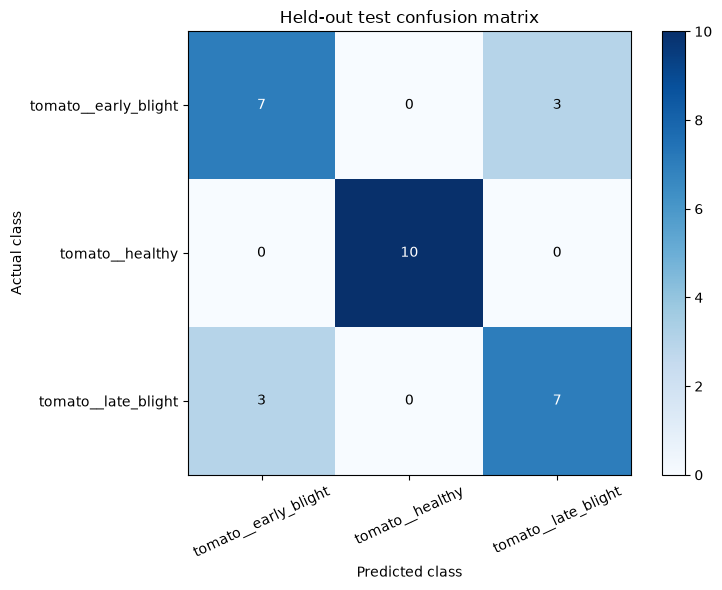

In [13]:
test_data = ImageFolder(DATA_ROOT / "test", loader=load_leaf)
assert test_data.class_to_idx == expected_mapping and len(test_data) == 30
test_loader = DataLoader(
    test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
)
test_metrics = evaluate(restored_model, test_loader, loss_fn)
test_metrics["selected_epoch"] = checkpoint["epoch"]
test_metrics["checkpoint_selection"] = "minimum validation loss"
test_metrics["sample_count"] = len(test_data)
(run_dir / "test_metrics.json").write_text(json.dumps(test_metrics, indent=2))

print(f"Selected epoch: {checkpoint['epoch']}")
print(f"Test accuracy: {test_metrics['accuracy']:.1%}")
print(f"Test macro F1: {test_metrics['macro_f1']:.3f}")
print(f"Test loss: {test_metrics['loss']:.4f}")
for row in test_metrics["per_class"]:
    print(
        f"{row['class_name']:23s} | precision {row['precision']:.3f} "
        f"recall {row['recall']:.3f} F1 {row['f1']:.3f} | count {row['support']}"
    )

# Save per-image predictions to make errors traceable to filenames.
test_prediction_rows = []
for path, target_index in test_data.samples:
    result = predict_image(path, restored_model, checkpoint["classes"])
    test_prediction_rows.append({
        "image_path": Path(path).relative_to(DATA_ROOT).as_posix(),
        "actual_class": class_names[target_index],
        "predicted_class": result["label"],
        "score": result["score"],
        "correct": result["label"] == class_names[target_index],
    })
with (run_dir / "test_predictions.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(test_prediction_rows[0]))
    writer.writeheader()
    writer.writerows(test_prediction_rows)
assert sum(row["correct"] for row in test_prediction_rows) == round(
    test_metrics["accuracy"] * len(test_data)
)

matrix = test_metrics["confusion_matrix"]
figure, axis = plt.subplots(figsize=(8, 6))
heatmap = axis.imshow(matrix, cmap="Blues")
figure.colorbar(heatmap, ax=axis)
axis.set_xticks(range(len(class_names)), labels=class_names, rotation=25)
axis.set_yticks(range(len(class_names)), labels=class_names)
axis.set(xlabel="Predicted class", ylabel="Actual class", title="Held-out test confusion matrix")
for actual in range(len(class_names)):
    for predicted in range(len(class_names)):
        count = matrix[actual][predicted]
        text_color = "white" if count > max(map(max, matrix)) / 2 else "black"
        axis.text(predicted, actual, str(count), ha="center", va="center", color=text_color)
figure.tight_layout()
figure.savefig(run_dir / "test_confusion_matrix.png", dpi=160)
plt.show()

## 13. Inspect example test predictions and save the experiment summary

The example grid includes up to three errors and three correct predictions, sorted
by their maximum softmax score. Use the source labels and filenames to investigate
errors. This inspection follows selection and final evaluation for this recipe.

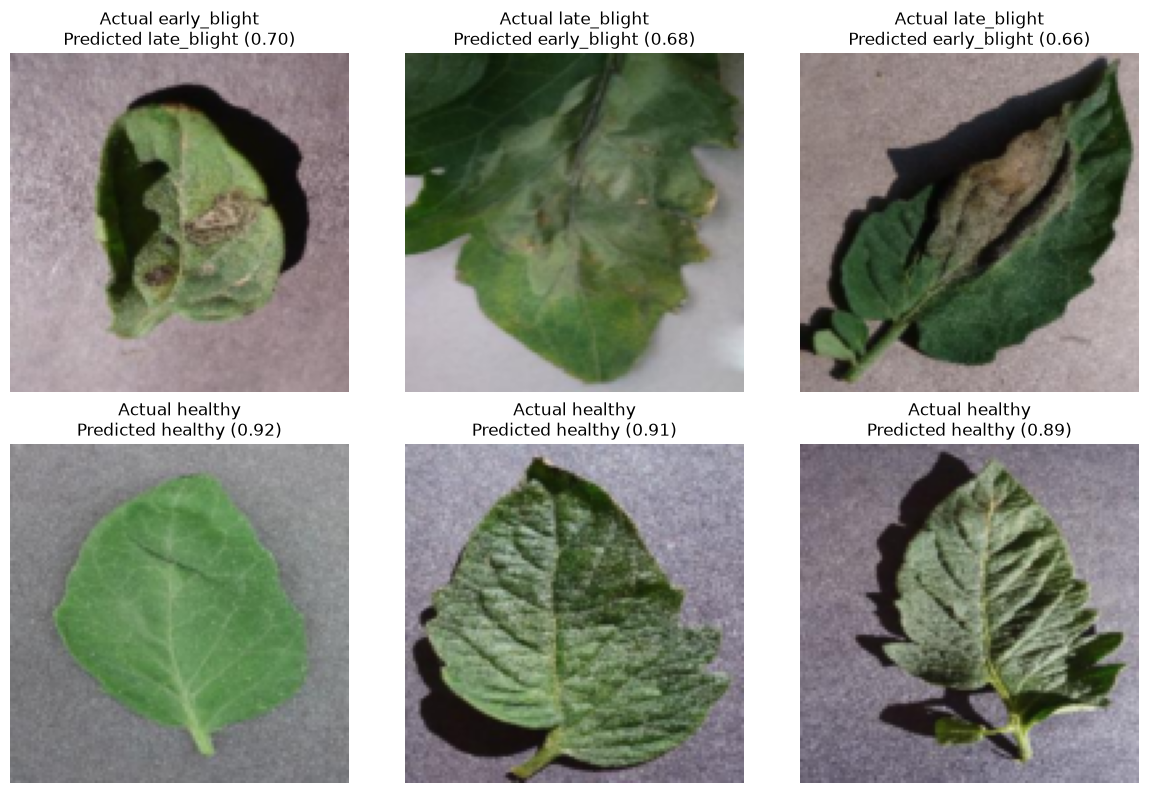

{
  "experiment": "second dataset baseline",
  "dataset": "Plant_CNN_Starter_300",
  "train_images": 210,
  "validation_images": 60,
  "test_images": 30,
  "trainable_parameters": 23891,
  "completed_epochs": 10,
  "selected_epoch": 9,
  "validation_accuracy": 0.8166666666666667,
  "validation_macro_f1": 0.818688690662384,
  "test_accuracy": 0.8,
  "test_macro_f1": 0.800000011920929,
  "checkpoint_reload_verified": true,
  "checkpoint_path": "runs/leafcheck_starter300/20261115T230136_680592Z/best_model.pt"
}
Saved outputs: /Users/jacobamey/Desktop/Brockport_Class/ML-Final-Project/runs/leafcheck_starter300/20261115T230136_680592Z


In [14]:
ranked_rows = sorted(test_prediction_rows, key=lambda row: row["score"], reverse=True)
examples = (
    [row for row in ranked_rows if not row["correct"]][:3]
    + [row for row in ranked_rows if row["correct"]][:3]
)
figure, axes = plt.subplots(2, 3, figsize=(12, 8))
for axis in axes.flat:
    axis.axis("off")
for axis, row in zip(axes.flat, examples):
    image = load_leaf(DATA_ROOT / row["image_path"])
    actual = row["actual_class"].removeprefix("tomato__")
    predicted = row["predicted_class"].removeprefix("tomato__")
    axis.imshow(image.permute(1, 2, 0))
    axis.set_title(f"Actual {actual}\nPredicted {predicted} ({row['score']:.2f})")
figure.tight_layout()
figure.savefig(run_dir / "test_prediction_examples.png", dpi=160)
plt.show()

summary = {
    "experiment": "second dataset baseline",
    "dataset": DATA_ROOT.name,
    "train_images": len(train_data),
    "validation_images": len(validation_data),
    "test_images": len(test_data),
    "trainable_parameters": sum(p.numel() for p in restored_model.parameters() if p.requires_grad),
    "completed_epochs": len(history),
    "selected_epoch": checkpoint["epoch"],
    "validation_accuracy": validation_metrics["accuracy"],
    "validation_macro_f1": validation_metrics["macro_f1"],
    "test_accuracy": test_metrics["accuracy"],
    "test_macro_f1": test_metrics["macro_f1"],
    "checkpoint_reload_verified": True,
    "checkpoint_path": checkpoint_path.relative_to(PROJECT_ROOT).as_posix(),
}
(run_dir / "experiment_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))
print("Saved outputs:", run_dir)

## Review and report the second experiment

Save the executed notebook. The run folder contains the selected checkpoint, class
mapping, configuration, dataset audit, manifests, tiny-set history, epoch log,
learning curves, validation and test metrics, confusion matrices, test predictions,
example predictions, and the experiment summary.

Explain why the 15 images are training copies, how groups remain separated, why
checkpoint selection uses validation, and why 30 test images give a rough estimate.
The supplied manifests identify parent groups and source paths, while class labels
are inherited annotations. A label audit or a more extensive near-duplicate review
could still reveal additional issues. Broad claims about a larger crop-disease task
require evaluation on that broader label set and representative images.

The earlier experiment and this run use different development and evaluation
images and different split sizes. Report both configurations and avoid attributing
score differences solely to model quality. A controlled architecture or augmentation
comparison should use the same dataset and splits for both variants.

The architecture and implementation in this notebook were supplied with AI
assistance. Record assistance according to your course policy, and explain each
decision in your own words.

References include the [dataset README](Plant_CNN_Starter_300/README.md),
[PyTorch optimization tutorial](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html),
[cross-entropy documentation](https://docs.pytorch.org/docs/2.15/generated/torch.nn.CrossEntropyLoss.html),
and [saving and loading guide](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html).